# Does Stopping Mean the Perceptron Has Learned?

Code for the A2 report (Option 1): the perceptron and two repairs (pocket, averaged), implemented from
scratch in NumPy, on synthetic data generated here. All explanation, proofs and discussion are in the
report (PDF).

> **Research question:** the perceptron is guaranteed to stop. Does stopping mean it has learned anything?

In [1]:
# Environment setup: numpy, pandas and matplotlib (already on Colab; installed here if missing)
import subprocess, sys
try:
    import numpy, pandas, matplotlib
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'numpy', 'pandas', 'matplotlib'])

In [2]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import display

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

---
## 1. Model

Rosenblatt's perceptron (report §3): on a mistake, $y_i w^\top x_i \le 0$, update $w \leftarrow w + \eta\,y_i x_i$.
The bias is a constant 1 added to every input. One `fit` gives three answers (the textbook last
weights, the pocket and the average) and, if `w_star` is given, records the two quantities of the
proof after every mistake.

In [3]:
class Perceptron:
    def __init__(self, lr=1.0, max_epochs=10_000):
        self.lr = lr
        self.max_epochs = max_epochs

    @staticmethod
    def add_bias(X):
        X = np.asarray(X, float)
        return np.hstack([X, np.ones((len(X), 1))])

    def fit(self, X, y, w_star=None):
        """If w_star is given, record the two quantities of Novikoff's proof after every mistake."""
        Xa = self.add_bias(X)
        y = np.asarray(y, int)
        n, d = Xa.shape
        assert set(np.unique(y)) <= {-1, 1}, 'labels must be -1 / +1'

        # start at w = 0 (the proof needs this)
        w = np.zeros(d)
        w_sum, steps = np.zeros(d), 0
        best_w, best_acc = w.copy(), -1.0
        self.total_mistakes, self.converged = 0, False
        self.mistakes_per_epoch, self.acc_per_epoch = [], []
        self.proj, self.normsq = [], []

        for epoch in range(self.max_epochs):
            errs = 0
            # same order every epoch (the leave-one-out argument needs a fixed order)
            for i in range(n):
                # a mistake is y_i * w.x_i <= 0; 0 counts, so the algorithm can leave w = 0
                if y[i] * (Xa[i] @ w) <= 0:
                    w = w + self.lr * y[i] * Xa[i]
                    errs += 1
                    if w_star is not None:
                        self.proj.append(w @ w_star)
                        self.normsq.append(w @ w)
                # averaged perceptron: running sum of w after every example
                w_sum += w
                steps += 1

            acc = np.mean(np.where(Xa @ w >= 0, 1, -1) == y)
            self.mistakes_per_epoch.append(errs)
            self.acc_per_epoch.append(acc)
            self.total_mistakes += errs
            # pocket: keep the best w seen at the end of an epoch
            if acc > best_acc:
                best_acc, best_w = acc, w.copy()
            if errs == 0:
                self.converged = True
                break

        self.w_last = w
        self.w_pocket = best_w
        self.w_avg = w_sum / steps
        return self


def perceptron_loss(w, X, y):
    return np.mean(np.maximum(0, -y * (Perceptron.add_bias(X) @ w)))

def predict(w, X):
    return np.where(Perceptron.add_bias(X) @ w >= 0, 1, -1)

def accuracy(w, X, y):
    return np.mean(predict(w, X) == y)

---
## 2. Data and the bound

`make_separable` draws points on the unit sphere and keeps only those at least $\gamma$ from a hidden
boundary $w^\star$, so the margin is known. Novikoff's bound is $(R/\gamma)^2$ mistakes (report §4);
`bound_inputs` measures $R$ and $\gamma$ after adding the bias coordinate.

In [4]:
def make_separable(n, d, gamma, seed=0, w_star=None):
    """Passing an existing w_star draws more points from the same distribution."""
    rng = np.random.default_rng(seed)
    if w_star is None:
        w_star = rng.normal(size=d)
        w_star /= np.linalg.norm(w_star)
    X = []
    while len(X) < n:
        # Gaussian points divided by their length are uniform on the sphere
        b = rng.normal(size=(4 * n, d))
        b /= np.linalg.norm(b, axis=1, keepdims=True)
        # keep only points at least gamma away from the boundary
        X.extend(b[np.abs(b @ w_star) >= gamma])
    X = np.array(X[:n])
    y = np.where(X @ w_star > 0, 1, -1)
    return X, y, w_star

def bound_inputs(X, y, w_star):
    Xa = Perceptron.add_bias(X)
    R = np.max(np.linalg.norm(Xa, axis=1))
    # the true boundary goes through the origin, so its bias weight is 0
    w_star_a = np.append(w_star, 0.0)
    gamma = np.min(y * (Xa @ w_star_a))
    return R, gamma, w_star_a

X0, y0, ws0 = make_separable(n=200, d=5, gamma=0.10, seed=1)
R, gamma, ws0_a = bound_inputs(X0, y0, ws0)
model = Perceptron().fit(X0, y0, w_star=ws0_a)
print(f'R = {R:.3f}, gamma = {gamma:.4f}, bound (R/gamma)^2 = {(R / gamma) ** 2:.0f}')
print(f'actual mistakes = {model.total_mistakes}, epochs = {len(model.mistakes_per_epoch)}')

R = 1.414, gamma = 0.1018, bound (R/gamma)^2 = 193
actual mistakes = 18, epochs = 2


---
## 3. Checking the proof during training

The two inequalities of the proof at every mistake: (a) $w_k^\top w^\star \ge k\gamma$ and
(b) $\|w_k\|^2 \le kR^2$ (report §4.2, §6.1, Figure 7).

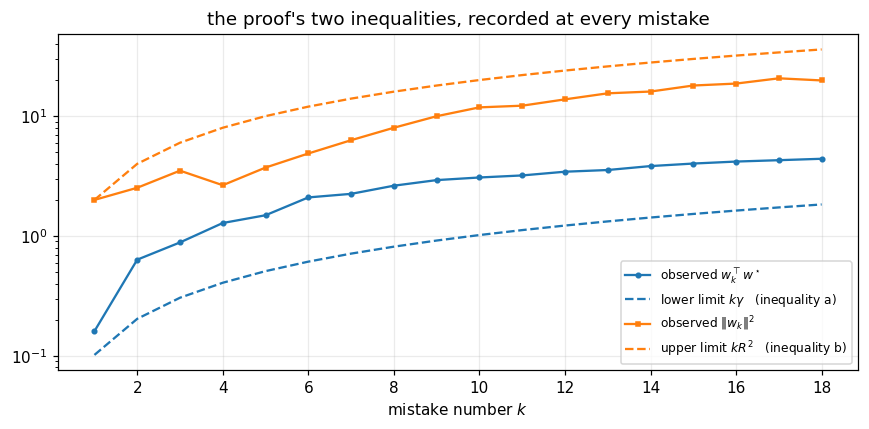

(a) held at all 18 mistakes: True   (b) held at all 18 mistakes: True


In [5]:
proj, normsq = np.array(model.proj), np.array(model.normsq)
k = np.arange(1, len(proj) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k, proj, 'o-', ms=3, color='tab:blue', label=r'observed $w_k^\top w^\star$')
ax.plot(k, k * gamma, '--', color='tab:blue', label=r'lower limit $k\gamma$   (inequality a)')
ax.plot(k, normsq, 's-', ms=3, color='tab:orange', label=r'observed $\|w_k\|^2$')
ax.plot(k, k * R ** 2, '--', color='tab:orange', label=r'upper limit $kR^2$   (inequality b)')
ax.set_yscale('log')
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel('mistake number $k$')
ax.set_title("the proof's two inequalities, recorded at every mistake")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

a_ok = np.all(proj >= k * gamma - 1e-9)       # tiny tolerance for rounding
b_ok = np.all(normsq <= k * R ** 2 + 1e-9)
print(f'(a) held at all {len(k)} mistakes: {a_ok}   (b) held at all {len(k)} mistakes: {b_ok}')

---
## 4. Does stopping mean learning?

200 points in 500 dimensions: coin-flip labels (nothing to learn) against labels from a real rule
(report §6.2).

In [6]:
def trial(name, X, y, X_new, y_new):
    m = Perceptron().fit(X, y)
    return {'labels': name, 'stopped': m.converged,
            'train error': 1 - accuracy(m.w_last, X, y),
            'mistakes / (n+1)': m.total_mistakes / (len(y) + 1),
            'true error': 1 - accuracy(m.w_last, X_new, y_new)}

rows = []
for s in range(3):
    # coin-flip labels: points on the sphere (no margin), random +1/-1 labels
    rng = np.random.default_rng(s)
    X, _, _ = make_separable(200, 500, 0.0, seed=10 + s)
    X_new, _, _ = make_separable(5000, 500, 0.0, seed=20 + s)
    rows.append(trial('coin flip', X, rng.choice([-1, 1], 200), X_new, rng.choice([-1, 1], 5000)))
for s in range(3):
    # labels from a real rule w* with margin 0.10
    X, y, w_star = make_separable(200, 500, 0.10, seed=s)
    X_new, y_new, _ = make_separable(5000, 500, 0.10, seed=30 + s, w_star=w_star)
    rows.append(trial('real rule', X, y, X_new, y_new))
display(pd.DataFrame(rows).set_index('labels').round(3))

,stopped,train error,mistakes / (n+1),true error
labels,,,,
coin flip,True,0.0,1.264,0.497
coin flip,True,0.0,1.134,0.496
coin flip,True,0.0,1.423,0.492
real rule,True,0.0,0.199,0.026
real rule,True,0.0,0.169,0.022
real rule,True,0.0,0.199,0.015


The leave-one-out bound $(R/\gamma)^2/(n+1)$ against the true error measured on 200,000 new points,
with 20 training sets for each $n$ (report §4.4, §6.2, Figure 9).

,mistakes,mistakes / (n+1),bound (R/gamma)^2/(n+1),true error
n,,,,
30,11.6,0.37419,6.45161,0.04683
100,18.5,0.18317,1.98020,0.00704
300,23.5,0.07807,0.66445,0.00208
1000,28.0,0.02797,0.19980,0.00039
3000,33.2,0.01106,0.06664,0.00001


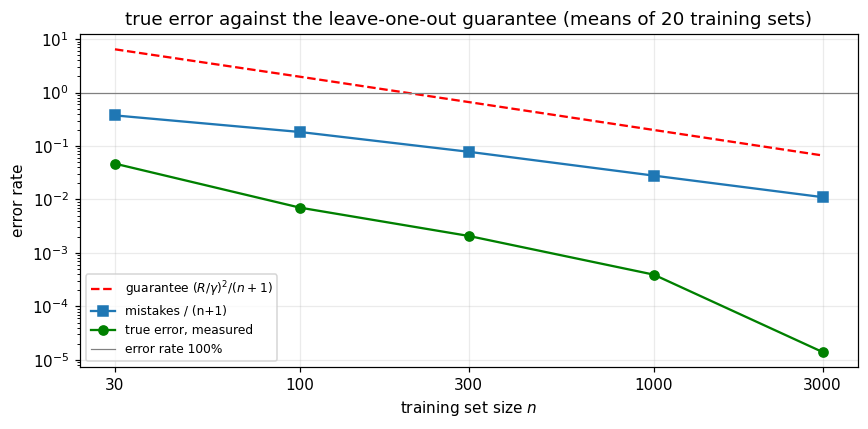

true error below the bound at every n: True
Hoeffding (95%) for a true error measured on 200,000 points: +/- 0.0030


In [7]:
# one fixed distribution (its w*) for every training set
ws = np.random.default_rng(21).normal(size=5)
ws /= np.linalg.norm(ws)
# 200,000 fresh points from it, never trained on, to measure the true error
Xt, yt, _ = make_separable(200_000, d=5, gamma=0.10, seed=999, w_star=ws)
# (R/gamma)^2 with R^2 = 1 + 1 (unit sphere + bias coordinate) and gamma = 0.10
BOUND = 2 / 0.10 ** 2

rows = []
for n in [30, 100, 300, 1000, 3000]:
    fits = []
    for s in range(1000, 1020):
        X, y, _ = make_separable(n, d=5, gamma=0.10, seed=s, w_star=ws)
        fits.append(Perceptron().fit(X, y))
    M = np.mean([f.total_mistakes for f in fits])
    err = np.mean([1 - accuracy(f.w_last, Xt, yt) for f in fits])
    rows.append({'n': n, 'mistakes': M, 'mistakes / (n+1)': M / (n + 1),
                 'bound (R/gamma)^2/(n+1)': BOUND / (n + 1), 'true error': err})
lc = pd.DataFrame(rows).set_index('n')
display(lc.round(5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(lc.index, lc['bound (R/gamma)^2/(n+1)'], 'r--', label=r'guarantee $(R/\gamma)^2/(n+1)$')
ax.loglog(lc.index, lc['mistakes / (n+1)'], 's-', label='mistakes / (n+1)')
ax.loglog(lc.index, lc['true error'], 'o-', color='green', label='true error, measured')
ax.axhline(1, color='grey', lw=0.8, label='error rate 100%')
ax.set_xticks(lc.index, labels=[str(n) for n in lc.index])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel('training set size $n$')
ax.set_ylabel('error rate')
ax.legend(fontsize=8)
ax.set_title('true error against the leave-one-out guarantee (means of 20 training sets)')
plt.tight_layout()
plt.show()

print('true error below the bound at every n:', (lc['true error'] <= lc['bound (R/gamma)^2/(n+1)']).all())
h = np.sqrt(np.log(2 / 0.05) / (2 * len(yt)))
print(f'Hoeffding (95%) for a true error measured on {len(yt):,} points: +/- {h:.4f}')

---
## 5. Noisy labels

Each label is flipped with probability 0.06, so no separating hyperplane exists (report §6.3, Figure 10).

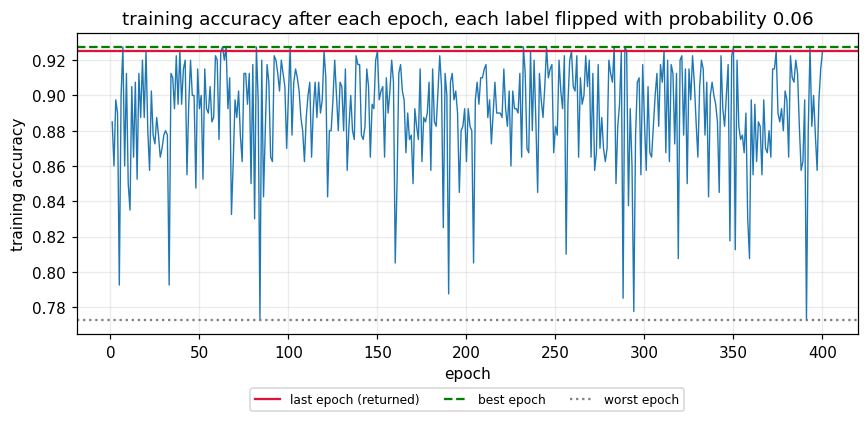

converged: False | mistakes in the last 5 epochs: [64, 78, 76, 68, 76]
training accuracy: returned (last epoch) 0.9250 | best 0.9275 at epoch 7 | worst 0.7725


In [8]:
# the hidden rule of the noisy experiments
wsn = np.random.default_rng(41).normal(size=5)
wsn /= np.linalg.norm(wsn)

def draw(n, seed, flip=0.06):
    """n points with margin 0.10 around wsn; each label is then flipped with probability 0.06."""
    X, y, _ = make_separable(n, d=5, gamma=0.10, seed=seed, w_star=wsn)
    # a second random stream from the same seed decides which labels flip
    flipped = np.random.default_rng([seed, 1]).random(n) < flip
    return X, np.where(flipped, -y, y)

Xn, yn = draw(400, seed=42)
# no separator exists, so the epoch cap is what stops training
noisy = Perceptron(max_epochs=400).fit(Xn, yn)
acc = np.array(noisy.acc_per_epoch)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(acc) + 1), acc, lw=0.9)
ax.axhline(acc[-1], color='crimson', label='last epoch (returned)')
ax.axhline(acc.max(), color='green', ls='--', label='best epoch')
ax.axhline(acc.min(), color='grey', ls=':', label='worst epoch')
ax.set_title('training accuracy after each epoch, each label flipped with probability 0.06')
ax.set_xlabel('epoch')
ax.set_ylabel('training accuracy')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.tight_layout()
plt.show()

print(f'converged: {noisy.converged} | mistakes in the last 5 epochs: {noisy.mistakes_per_epoch[-5:]}')
print(f'training accuracy: returned (last epoch) {acc[-1]:.4f} | best {acc.max():.4f} '
      f'at epoch {acc.argmax() + 1} | worst {acc.min():.4f}')

---
## 6. Two repairs, and choosing between them

Vanilla, pocket and averaged are compared on new validation data. The chosen one is tested once with
a Hoeffding interval and compared with its true accuracy and with $w^\star$ itself (report §7, §8).

In [9]:
(Xva, yva), (Xte, yte), (Xtrue, ytrue) = draw(2000, 100), draw(2000, 200), draw(200_000, 300)

# the three answers of the noisy run above
cands = {'vanilla': noisy.w_last, 'pocket': noisy.w_pocket, 'averaged': noisy.w_avg}
rows = []
for name, w in cands.items():
    rows.append({'train acc': accuracy(w, Xn, yn),
                 'val acc': accuracy(w, Xva, yva),
                 'val perceptron loss': perceptron_loss(w, Xva, yva),
                 '||w||': np.linalg.norm(w)})
tab = pd.DataFrame(rows, index=list(cands))
display(tab.round(4))

# choose on validation only, then use the test set once
chosen = tab['val acc'].idxmax()
test = accuracy(cands[chosen], Xte, yte)
true = accuracy(cands[chosen], Xtrue, ytrue)
# Hoeffding (module 3.9), 95%, for one fixed classifier on m test points
h = np.sqrt(np.log(2 / 0.05) / (2 * len(yte)))
print(f'chosen on validation: {chosen}')
print(f'test accuracy {test:.4f} +/- {h:.4f} | true accuracy {true:.4f} | inside: {abs(test - true) <= h}')
print(f'ceiling (w* itself), true accuracy: {accuracy(np.append(wsn, 0.0), Xtrue, ytrue):.4f}')

,train acc,val acc,val perceptron loss,||w||
vanilla,0.9250,0.9265,0.1273,4.0074
pocket,0.9275,0.9310,0.0851,2.6511
averaged,0.9275,0.9270,0.1100,3.4355


chosen on validation: pocket
test accuracy 0.9370 +/- 0.0304 | true accuracy 0.9401 | inside: True
ceiling (w* itself), true accuracy: 0.9401


In [10]:
# one training sample is one draw of luck: repeat on 20 fresh ones, score each on the truth
runs = []
for s in range(20):
    f = Perceptron(max_epochs=400).fit(*draw(400, 1000 + s))
    runs.append([accuracy(w, Xtrue, ytrue) for w in (f.w_last, f.w_pocket, f.w_avg)])
reps = pd.DataFrame(runs, columns=['vanilla', 'pocket', 'averaged'])
display(reps.agg(['mean', 'std', 'min', 'max']).round(4))

,vanilla,pocket,averaged
mean,0.8591,0.9298,0.9381
std,0.0644,0.0209,0.0034
min,0.7492,0.8471,0.9282
max,0.9401,0.9401,0.9401


---
## 7. Answer

Not by itself: with coin-flip labels the perceptron stops but scores about 50% on new points. With
i.i.d. data from a distribution that has a margin, its expected true error is at most
$(R/\gamma)^2/(n+1)$, and the measured true error is below that bound at every $n$. Full answer:
report §9.1.